# 01 — Exploration


In [1]:
import sys, subprocess
print("Python du kernel :", sys.executable)
r = subprocess.run([sys.executable, "-m", "pip", "install",
                    "pandas", "numpy", "scipy", "scikit-learn",
                    "networkx", "matplotlib", "pyarrow"],
                   capture_output=True, text=True)
print(r.stdout[-1200:])
print(r.stderr[-1200:])
import sys, os
sys.path.append("..")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src.data_loader import load, split_per_user, save_processed
DATA = "../data/raw/interactions_real_rich_processed.csv"
df = load(DATA)
train, test = split_per_user(df)

Python du kernel : c:\Users\latro\AppData\Local\Programs\Python\Python313\python.exe
kages (from matplotlib) (4.62.1)
Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl (8.2 MB)
Using cached pyarrow-26.0.1-cp313-cp313-win_amd64.whl (29.0 MB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
Using cached threadpoolctl-3.8.0-py3-none-any.whl (32 kB)


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



In [2]:
nu, ns = df.user_id_new.nunique(), df.skill_id_new.nunique()
print(df.shape, nu, ns, f'densité {len(df)/(nu*ns):.2%}')
df.describe()

(41982, 3) 4163 123 densité 8.20%


,user_id_new,skill_id_new,target_correct_rate
count,41982.000000,41982.000000,41982.000000
mean,1766.443785,48.153804,0.708472
std,1390.487846,31.278912,0.321648
min,0.000000,0.000000,0.000000
25%,676.000000,22.000000,0.521739
50%,1167.000000,44.000000,0.800000
75%,3031.000000,79.000000,1.000000
max,4162.000000,122.000000,1.000000


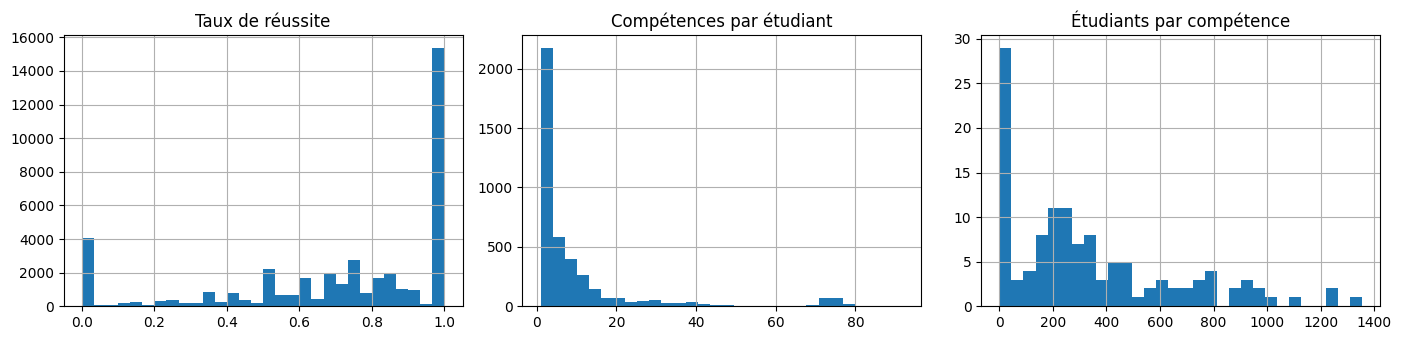

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
df.target_correct_rate.hist(bins=30, ax=ax[0]); ax[0].set_title('Taux de réussite')
df.groupby('user_id_new').size().hist(bins=30, ax=ax[1]); ax[1].set_title('Compétences par étudiant')
df.groupby('skill_id_new').size().hist(bins=30, ax=ax[2]); ax[2].set_title('Étudiants par compétence')
plt.tight_layout()

In [4]:
print(save_processed(df, '../data/processed/interactions.parquet'))

../data/processed/interactions.parquet
